*Mathematical Foundations of Robotics · Chapter 5 — Velocity Kinematics, Jacobians, Singularities and Statics*

# 5.1 Velocity of Rigid Bodies and Velocity Propagation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/05-velocity-kinematics-and-statics/5.1-velocity-of-rigid-bodies-and-propagation.ipynb)


Chapters 2–4 described a manipulator as a purely geometric object: a set of joint angles fixes the pose of the tool,
and nothing is said about *how fast* anything moves. This notebook adds time. We define the linear and angular velocity
of a rigid body, show how velocities are described in different frames and how they combine, and derive the **velocity
propagation** iteration of Craig's Chapter 5, which finds the velocity of every link — and therefore of the tool — from
the joint rates by a short recursion. That recursion is the machine from which the Jacobian of Notebook 5.2 is built. All
results are verified by finite differences, and the recursion is compared with MuJoCo's own velocity computation for a
real UR5e.

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., Ch. 5, §5.1–5.5 (notation for time-varying quantities; linear and rotational velocity of rigid bodies; more on angular velocity; motion of the links of a robot; velocity “propagation” from link to link) |
| **Parallel reading** | Lynch & Park §3.2.2 (angular velocities) and §3.3.2 (twists) · Siciliano et al. Ch. 3 (derivative of a rotation matrix, link velocities) · Corke *RVC* Ch. 8 · Spong et al., the chapter on velocity kinematics |
| **Lectures** | [Modern Robotics — Ch. 5 Velocity kinematics and statics](https://www.youtube.com/watch?v=6tj8QLF69Ok) · [Modern Robotics — 3.2.2 Angular velocities](https://www.youtube.com/watch?v=zJJldJYMxVU) · [ThatsEngineering — Jacobian matrix and singularities (part 1)](https://www.youtube.com/watch?v=h2YM0CDzDl4) |
| **Prerequisites** | Chapter 2 (rotation matrices, homogeneous transforms) and Chapter 3 (Denavit–Hartenberg forward kinematics) |
| **Study time** | about 3 hours |

## Learning objectives

1. Distinguish the velocity of a point *observed from* a frame from the same vector *described in* another frame.
2. Derive the angular velocity $\boldsymbol\omega$ of a rotating frame from $\dot R R^{\mathsf T}$, and explain why it is a vector although finite rotations are not.
3. Compute the velocity of a point that is fixed to, or moves on, a moving rigid body: $\mathbf v = \mathbf v_O + \boldsymbol\omega\times\mathbf r$.
4. Add angular velocities correctly: only when they are written in the same frame.
5. State and apply the outward **velocity propagation** equations for revolute and prismatic joints.
6. Reproduce the tool velocity of a real six-axis arm from its D-H table and compare it with the simulator.

## Contents

1. [From pose to motion](#1.-From-pose-to-motion)
2. [The velocity of a point](#2.-The-velocity-of-a-point)
3. [Angular velocity](#3.-Angular-velocity)
4. [Velocity of a point on a moving rigid body](#4.-Velocity-of-a-point-on-a-moving-rigid-body)
5. [Adding angular velocities](#5.-Adding-angular-velocities)
6. [Velocity propagation from link to link](#6.-Velocity-propagation-from-link-to-link)
7. [A planar example, symbolically and in motion](#7.-A-planar-example,-symbolically-and-in-motion)
8. [A real robot: the UR5e flange velocity](#8.-A-real-robot:-the-UR5e-flange-velocity)
9. [Worked examples](#9.-Worked-examples)
10. [Summary, common mistakes and exercises](#10.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit.transforms import rotx, roty, rotz, rot_axis_angle, make_T, inv_T, skew, unskew, transl
from rgkit.kinematics import fk_dh, fk_tool
from rgkit import jacobian as jc

## 1. From pose to motion

The forward kinematics of Chapter 3 is a function $\mathbf x = f(\mathbf q)$ from joint variables to the pose of the tool. A
robot, however, does not jump from one pose to the next: it moves along a *path* $\mathbf q(t)$, and what the application
usually specifies is how the tool should move — "follow this seam at 20 mm/s", "keep the camera pointing at the part while
the arm translates". Differentiating $f$ along the path produces the **velocity** of the tool,
$\dot{\mathbf x} = \tfrac{\partial f}{\partial\mathbf q}\dot{\mathbf q}$, and the matrix $\partial f/\partial\mathbf q$ is the
**Jacobian** studied from Notebook 5.2 onward. The position part of that derivative is routine calculus. The orientation
part is not, because a rotation matrix has nine entries but only three degrees of freedom, so its derivative has to be
interpreted. The first half of this notebook is therefore about rigid-body velocity as such; the second half uses it to
compute link velocities.

> **Key idea.** The motion of a rigid body at one instant is described by **two vectors**: the angular velocity
> $\boldsymbol\omega$ of the body and the linear velocity $\mathbf v$ of one chosen point of the body. The velocity of
> every other point then follows.

## 2. The velocity of a point

Let ${}^{B}Q$ be the position vector of a point $Q$ described in a frame $\{B\}$. Its **velocity as observed from $\{B\}$** is the
time derivative of the three numbers ${}^{B}Q(t)$ (Craig, §5.2):

$$
{}^{B}V_Q = \frac{d}{dt}\,{}^{B}Q(t).
$$

This vector can then be *described* in any frame by rotating it, exactly as one rotates any free vector:
${}^{A}\!\left({}^{B}V_Q\right) = {}^{A}_{B}R\;{}^{B}V_Q$. Two things must not be confused:

* the **observer** of the motion (the frame whose origin is regarded as fixed — here $\{B\}$), and
* the **description** of the resulting vector (the frame whose axes are used to write down its components — here $\{A\}$).

When the observer is the universe frame $\{U\}$ one writes simply ${}^{U}V_Q$ and speaks of "the velocity of $Q$". The
derivative of a vector **does depend on the observer**. A point that is at rest in a room moves, as seen from a rotating
turntable, on a circle; the next section makes this precise. The velocity of the origin of a frame $\{B\}$ is the
special case ${}^{A}V_{BORG} = \frac{d}{dt}{}^{A}P_{BORG}$.

## 3. Angular velocity

A body rotating relative to a reference frame $\{A\}$ has an orientation ${}^{A}_{B}R(t)$ that changes with time. Because
$R R^{\mathsf T}=I$ for every $t$, differentiating gives

$$
\dot R\,R^{\mathsf T} + R\,\dot R^{\mathsf T} = \dot R\,R^{\mathsf T} + \big(\dot R\,R^{\mathsf T}\big)^{\mathsf T} = 0 ,
$$

so the matrix $S=\dot R R^{\mathsf T}$ equals minus its own transpose: it is **skew-symmetric**. Every $3\times 3$
skew-symmetric matrix has the form $[\boldsymbol\omega]_\times$ (the matrix of the cross product,
`rgkit.transforms.skew`), so

$$
\boxed{\;\dot R\,R^{\mathsf T} = [\boldsymbol\omega]_\times \;}
\qquad\Longleftrightarrow\qquad
\dot R = [\boldsymbol\omega]_\times R .
$$

The vector $\boldsymbol\omega = {}^{A}\Omega_B$ is the **angular velocity** of $\{B\}$ relative to $\{A\}$, described in
$\{A\}$. Its meaning follows from a point $P$ that is *fixed in the body*: its description in $\{A\}$ is
${}^{A}P = R\,{}^{B}P$ with ${}^{B}P$ constant, hence

$$
{}^{A}\dot P = \dot R\,{}^{B}P = \dot R R^{\mathsf T}\,{}^{A}P = \boldsymbol\omega\times{}^{A}P .
$$

Every body-fixed vector turns about the axis $\hat{\boldsymbol\omega}$ at the rate $\lVert\boldsymbol\omega\rVert$. For a rotation
about a fixed axis $\hat K$ by $\theta(t)$ this gives $\boldsymbol\omega=\dot\theta\,\hat K$, in agreement with intuition.

**Two ways of writing the same vector.** The matrix $R^{\mathsf T}\dot R$ is also skew; it equals $[\boldsymbol\omega_b]_\times$
with $\boldsymbol\omega_b=R^{\mathsf T}\boldsymbol\omega$, the same angular velocity *described in the rotating frame*. The
two are related by an ordinary change of frame, and the choice between them is a matter of bookkeeping. Craig and the
whole of this notebook use ${}^{A}\Omega_B$, written in a fixed frame ("spatial" angular velocity); Lynch & Park use both,
calling the second the *body* angular velocity.

In [2]:
# Numerical check of  Rdot R^T = [w]x  for a motion with all three angles changing
def R_of_t(t):
    return rotz(0.6 * t) @ roty(0.4 * t + 0.3) @ rotx(-0.5 * t)

t0, h = 0.7, 1e-6
R0 = R_of_t(t0)
Rdot = (R_of_t(t0 + h) - R_of_t(t0 - h)) / (2 * h)               # central difference
S = Rdot @ R0.T
print("R Rdot^T symmetric part (should be 0):", np.abs(S + S.T).max().round(10))
w_space = unskew(S)
w_body = unskew(R0.T @ Rdot)
print("omega (spatial):", w_space.round(4))
print("omega (body)   :", w_body.round(4), "  = R^T omega :", np.allclose(w_body, R0.T @ w_space))
print("jc.angular_velocity_space agrees:", np.allclose(jc.angular_velocity_space(R0, Rdot), w_space))

# a body-fixed vector turns with  omega x p
pB = np.array([0.3, -0.2, 0.5])
pA_dot = (R_of_t(t0 + h) @ pB - R_of_t(t0 - h) @ pB) / (2 * h)
print("d/dt (R pB) = omega x (R pB):", np.allclose(pA_dot, np.cross(w_space, R0 @ pB), atol=1e-8))

R Rdot^T symmetric part (should be 0): 1e-10
omega (spatial): [-0.545   0.1947  0.874 ]
omega (body)   : [-0.8288  0.2037  0.6086]   = R^T omega : True
jc.angular_velocity_space agrees: True
d/dt (R pB) = omega x (R pB): True


## 4. Velocity of a point on a moving rigid body

Now let the body $\{B\}$ also translate. Let ${}^{A}P_{BORG}(t)$ be the origin of $\{B\}$ and let a point $Q$ be described in
$\{B\}$ by ${}^{B}Q(t)$, which may itself change if $Q$ slides over the body. Its position in $\{A\}$ is

$$
{}^{A}Q = {}^{A}P_{BORG} + {}^{A}_{B}R\,{}^{B}Q .
$$

Differentiating with the product rule, and using $\dot R=[\boldsymbol\omega]_\times R$, gives Craig's general velocity formula

$$
\boxed{\;{}^{A}V_Q = {}^{A}V_{BORG} + {}^{A}_{B}R\,{}^{B}V_Q + {}^{A}\Omega_B\times{}^{A}_{B}R\,{}^{B}Q\;}
$$

The three terms are, in order: the velocity of the body's origin; the velocity of $Q$ *relative to the body*
(zero if $Q$ is fixed in it), rotated into $\{A\}$; and the velocity that the body's rotation imparts to a point at the
displacement ${}^{A}_{B}R\,{}^{B}Q$ from the origin. For a **point fixed in the body** the middle term vanishes and what remains is the
*rigid-body velocity formula*

$$
\mathbf v_Q = \mathbf v_O + \boldsymbol\omega\times\mathbf r_{OQ},\qquad \mathbf r_{OQ}=\overrightarrow{OQ}.
$$

Two consequences are used constantly. First, $\boldsymbol\omega$ is the **same for every point of the body**, whereas the
linear velocity depends on the point. Second, the pair $(\mathbf v_O,\boldsymbol\omega)$ is therefore all that must be known:
the velocity of every other body point is obtained from it. Such a pair is called a **twist** or *spatial velocity*; in this
chapter it is always written with the linear part on top, $\mathcal V = [\mathbf v;\ \boldsymbol\omega]\in\mathbb R^6$, so that it
matches the order of the Jacobian rows in Craig's book and in MuJoCo.

The explorer below draws the velocity field $\mathbf v_O+\boldsymbol\omega\times\mathbf r$ of a planar rigid body. When
$\omega\neq0$ there is always one point — the **instantaneous centre of rotation** — whose velocity is zero, and at which
the body *appears* to turn about a fixed pivot. For $\omega=0$ the field is uniform: a pure translation.

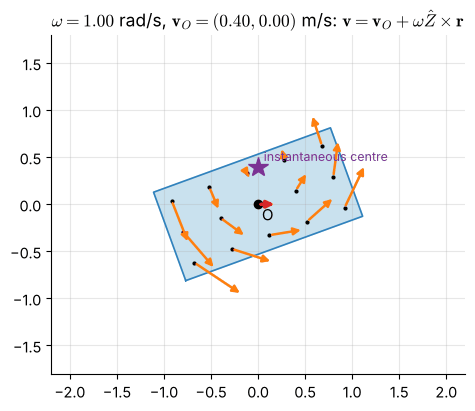

In [3]:
def field_demo(omega=1.0, vx=0.4, vy=0.0, theta_deg=20.0):
    th = np.radians(theta_deg)
    O = np.array([0.0, 0.0])
    corners = np.array([[-1.0, -0.5], [1.0, -0.5], [1.0, 0.5], [-1.0, 0.5], [-1.0, -0.5]]).T
    R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    pts = R @ corners
    fig, ax = plt.subplots(figsize=(6.2, 4.4))
    ax.fill(*pts, color="#9ecae1", alpha=0.55, zorder=1)
    ax.plot(*pts, color="#3182bd", lw=1.2)
    gx, gy = np.meshgrid(np.linspace(-0.85, 0.85, 5), np.linspace(-0.35, 0.35, 3))
    body_pts = R @ np.vstack([gx.ravel(), gy.ravel()])
    v_O = np.array([vx, vy])
    for p in body_pts.T:
        v = v_O + omega * np.array([-p[1], p[0]])                 # v_O + omega x r   (omega along +Z)
        ax.annotate("", xy=p + 0.5 * v, xytext=p, arrowprops=dict(arrowstyle="-|>", color="#ff7f0e", lw=1.8))
        ax.plot(*p, "k.", ms=4)
    ax.annotate("", xy=O + 0.5 * v_O, xytext=O, arrowprops=dict(arrowstyle="-|>", color="#d62728", lw=2.4))
    ax.plot(*O, "ko", ms=6); ax.text(0.04, -0.17, "O", fontsize=11)
    if abs(omega) > 1e-9:
        c = O + np.array([-v_O[1], v_O[0]]) / omega               # point where v_O + omega x (c - O) = 0
        ax.plot(*c, "*", color="#7b3294", ms=15, zorder=5)
        ax.text(c[0] + 0.06, c[1] + 0.06, "instantaneous centre", color="#7b3294", fontsize=9)
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-1.8, 1.8); ax.set_aspect("equal")
    ax.set_title(rf"$\omega={omega:.2f}$ rad/s, $\mathbf{{v}}_O=({vx:.2f},{vy:.2f})$ m/s: $\mathbf{{v}}=\mathbf{{v}}_O+\omega\hat Z\times\mathbf{{r}}$")
    plt.show()

interact(field_demo,
         omega=widgets.FloatSlider(value=1.0, min=-2.0, max=2.0, step=0.1, description="ω"),
         vx=widgets.FloatSlider(value=0.4, min=-1.0, max=1.0, step=0.1, description="v_Ox"),
         vy=widgets.FloatSlider(value=0.0, min=-1.0, max=1.0, step=0.1, description="v_Oy"),
         theta_deg=widgets.FloatSlider(value=20.0, min=-90, max=90, step=5, description="θ (deg)"))

## 5. Adding angular velocities

Finite rotations do not commute: turning $90^\circ$ about $\hat X$ and then about $\hat Z$ differs from the reverse order
(Notebook 2.2). **Angular velocities nevertheless add like ordinary vectors** — provided they are described in the same
frame. Let $\{B\}$ rotate relative to $\{A\}$ and $\{C\}$ rotate relative to $\{B\}$, so that ${}^{A}_{C}R={}^{A}_{B}R\,{}^{B}_{C}R$.
Differentiate and multiply on the right by ${}^{A}_{C}R^{\mathsf T}={}^{B}_{C}R^{\mathsf T}\,{}^{A}_{B}R^{\mathsf T}$:

$$
\dot R_{AC}R_{AC}^{\mathsf T}
=\dot R_{AB}R_{AB}^{\mathsf T} + R_{AB}\big(\dot R_{BC}R_{BC}^{\mathsf T}\big)R_{AB}^{\mathsf T}
=[{}^{A}\Omega_B]_\times + R_{AB}\,[{}^{B}\Omega_C]_\times R_{AB}^{\mathsf T}.
$$

The identity $R[\mathbf a]_\times R^{\mathsf T}=[R\mathbf a]_\times$ (a rotation carries the cross product with it) turns the last
term into $[R_{AB}\,{}^{B}\Omega_C]_\times$, and therefore

$$
\boxed{\;{}^{A}\Omega_C = {}^{A}\Omega_B + {}^{A}_{B}R\;{}^{B}\Omega_C\;}
$$

This is the rule that makes a serial manipulator tractable: the angular velocity of link $i+1$ is that of link $i$ plus the
joint rate about the joint axis, once both are described in the same frame.

**Caution — Euler-angle rates are not angular velocities.** The derivatives $\dot\alpha,\dot\beta,\dot\gamma$ of a three-angle
representation are *not* the components of $\boldsymbol\omega$ along any set of axes; they are related to it by a
configuration-dependent matrix that can be singular (Notebook 5.3). Only $\boldsymbol\omega$ itself obeys the addition rule above.

The figure applies the rule to a spinning top. Frame $\{B\}$ is tilted by $60^\circ$ and precesses about the vertical $\hat Z_A$
at $\dot\phi=0.5$ rad/s; the top spins relative to $\{B\}$ about $\hat Z_B$ at $2$ rad/s. The resulting angular velocity
points along neither axis.

A_Omega_C = A_Omega_B + R_AB B_Omega_C = [ 0.     -1.7321  1.5   ]
finite-difference value               = [ 0.     -1.7321  1.5   ]   agree: True


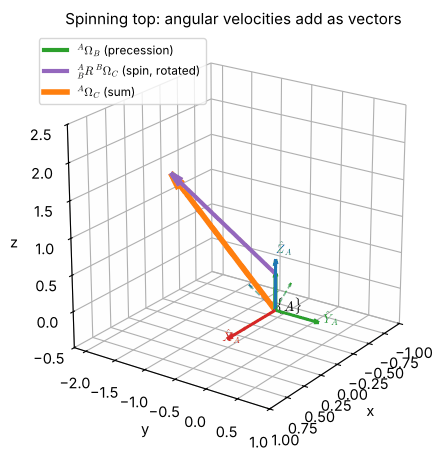

In [4]:
tilt = deg(60)
R_AB = rotx(tilt)                                       # frame B at the instant considered
Om_B = np.array([0.0, 0.0, 0.5])                        # precession, described in A
Om_C_in_B = np.array([0.0, 0.0, 2.0])                   # spin, described in B
Om_C = Om_B + R_AB @ Om_C_in_B
print("A_Omega_C = A_Omega_B + R_AB B_Omega_C =", Om_C.round(4))

# verification with a time-dependent rotation: R_AC(t) = Rz(0.5 t) Rx(60 deg) Rz(2 t)
RAC = lambda t: rotz(0.5 * t) @ rotx(tilt) @ rotz(2.0 * t)
h = 1e-6
w_num = unskew(((RAC(h) - RAC(-h)) / (2 * h)) @ RAC(0).T)
print("finite-difference value               =", w_num.round(4), "  agree:", np.allclose(w_num, Om_C, atol=1e-7))

ax = new_axes3d(lim=((-1.0, 1.0), (-2.2, 1.0), (-0.5, 2.5)), title="Spinning top: angular velocities add as vectors", figsize=(5.8, 5.2))
draw_frame(ax, np.eye(3), length=0.7, name="A", fontsize=9)
draw_frame(ax, R_AB, length=0.5, label_axes=False, lw=1.2, alpha=0.6, ls="--")
draw_vector(ax, [0, 0, 0], Om_B, color="#2ca02c", lw=3)
draw_vector(ax, Om_B, R_AB @ Om_C_in_B, color="#9467bd", lw=3)
draw_vector(ax, [0, 0, 0], Om_C, color="#ff7f0e", lw=4)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0], [0], color="#2ca02c", lw=3, label=r"${}^A\Omega_B$ (precession)"),
                   Line2D([0], [0], color="#9467bd", lw=3, label=r"${}^A_BR\,{}^B\Omega_C$ (spin, rotated)"),
                   Line2D([0], [0], color="#ff7f0e", lw=4, label=r"${}^A\Omega_C$ (sum)")], loc="upper left", fontsize=8.5)
plt.show()

## 6. Velocity propagation from link to link

We now apply these rules to a serial arm. Number the links $0,1,\dots,n$ from the fixed base, attach frame $\{i\}$ to link $i$
by the **modified (Craig) D-H convention**, and write the velocity of link $i$ as the pair
$({}^{i}\mathbf v_i,\ {}^{i}\boldsymbol\omega_i)$: the linear velocity of the **origin of frame $\{i\}$** and the angular
velocity of link $i$, both observed from the fixed base but *described in frame $\{i\}$ itself*. Describing every
quantity in the frame of the link that carries it means that the same few operations are repeated for each link.

**Revolute joint.** Frame $\{i+1\}$ sits on link $i+1$. Seen from link $i$, link $i+1$ merely turns about the joint axis
$\hat Z_{i+1}$ at the rate $\dot\theta_{i+1}$, so by the addition rule of Section 5

$$
{}^{i}\boldsymbol\omega_{i+1} = {}^{i}\boldsymbol\omega_i + {}^{i}_{i+1}R\,\dot\theta_{i+1}\,{}^{i+1}\hat Z_{i+1}
\;\;\Longrightarrow\;\;
\boxed{{}^{i+1}\boldsymbol\omega_{i+1} = {}^{i+1}_{i}R\,{}^{i}\boldsymbol\omega_i + \dot\theta_{i+1}\,{}^{i+1}\hat Z_{i+1}},
\qquad {}^{i+1}\hat Z_{i+1}=[0\ 0\ 1]^{\mathsf T}.
$$

The origin of $\{i+1\}$ lies *on the joint axis*, so the joint rotation does not move it; it is carried along by link $i$
exactly like a point fixed on that link, at the displacement ${}^{i}P_{i+1}$ from the origin of $\{i\}$. The rigid-body
formula of Section 4 therefore gives, after rotating into $\{i+1\}$,

$$
\boxed{{}^{i+1}\mathbf v_{i+1} = {}^{i+1}_{i}R\Big({}^{i}\mathbf v_i + {}^{i}\boldsymbol\omega_i\times{}^{i}P_{i+1}\Big)}.
$$

**Prismatic joint.** The orientation of link $i+1$ relative to link $i$ is fixed, so
${}^{i+1}\boldsymbol\omega_{i+1}={}^{i+1}_{i}R\,{}^{i}\boldsymbol\omega_i$, while the origin slides along $\hat Z_{i+1}$ at the rate
$\dot d_{i+1}$:

$$
{}^{i+1}\mathbf v_{i+1} = {}^{i+1}_{i}R\Big({}^{i}\mathbf v_i + {}^{i}\boldsymbol\omega_i\times{}^{i}P_{i+1}\Big) + \dot d_{i+1}\,{}^{i+1}\hat Z_{i+1}.
$$

> **Algorithm (outward iteration).**
> Start from the fixed base, ${}^{0}\boldsymbol\omega_0={}^{0}\mathbf v_0=\mathbf 0$. For $i=0,1,\dots,n-1$ apply the
> formulas above, where ${}^{i}_{i+1}R$ and ${}^{i}P_{i+1}$ are read from the link transform
> ${}^{i}_{i+1}T$ of the D-H table. The result ${}^{n}\mathbf v_n,\ {}^{n}\boldsymbol\omega_n$ is the velocity of the last frame, described
> in that frame; ${}^{0}\mathbf v_n={}^{0}_{n}R\,{}^{n}\mathbf v_n$ describes it in the base frame.
> For a tool frame $\{T\}$ that is rigidly attached to $\{n\}$, one more step with the *constant* transform
> ${}^{n}_{T}T$ gives its velocity.

The recursion needs $O(n)$ operations. Note what it does **not** need: no derivative of any kinematic expression is taken.
The derivatives have been done once and for all in the three rules (Sections 3–5); numbers are merely pushed along the chain.
`rgkit.jacobian.propagate_velocity(table, q, qd, tool=None)` implements it and returns the lists of $\boldsymbol\omega_i$ and
$\mathbf v_i$ for every link.

## 7. A planar example, symbolically and in motion

Consider the planar two-link arm of Craig's Example 5.1–5.2 type, with link lengths $L_1,L_2$. In the modified convention its D-H
table has the rows $(\alpha_{i-1},a_{i-1},d_i,\theta_i)=(0,0,0,\theta_1)$, $(0,L_1,0,\theta_2)$ and a fixed row $(0,L_2,0,0)$ for the tip
frame $\{3\}$. Propagating symbolically (all rotations are about $\hat Z$, so each ${}^{i+1}_iR$ is a planar rotation by $-\theta_{i+1}$):

In [5]:
import sympy as sp
t1, t2, w1, w2, L1, L2 = sp.symbols("theta1 theta2 thetadot1 thetadot2 L1 L2", real=True)

def Rz_sym(a):
    return sp.Matrix([[sp.cos(a), -sp.sin(a), 0], [sp.sin(a), sp.cos(a), 0], [0, 0, 1]])

zhat = sp.Matrix([0, 0, 1])
links = [(0, t1, w1), (L1, t2, w2), (L2, 0, 0)]                   # (a_{i-1}, theta_i, thetadot_i); last row fixed
w, v = sp.zeros(3, 1), sp.zeros(3, 1)                              # base at rest
for i, (a, th, thd) in enumerate(links, start=1):
    P = sp.Matrix([a, 0, 0])                                       # ^{i-1}P_i
    Rt = Rz_sym(th).T                                              # ^i_{i-1}R
    v = Rt * (v + w.cross(P))                                      # origin of {i}
    w = Rt * w + thd * zhat
    print(f"^{i}w_{i} =", list(map(sp.simplify, w)), "\n^%dv_%d =" % (i, i), list(map(sp.simplify, v)))
v3_tool = v
display(Math(r"{}^{3}\mathbf v_3 = " + sp.latex(sp.simplify(v3_tool))))

^1w_1 = [0, 0, thetadot1] 
^1v_1 = [0, 0, 0]
^2w_2 = [0, 0, thetadot1 + thetadot2] 
^2v_2 = [L1*thetadot1*sin(theta2), L1*thetadot1*cos(theta2), 0]
^3w_3 = [0, 0, thetadot1 + thetadot2] 
^3v_3 = [L1*thetadot1*sin(theta2), L1*thetadot1*cos(theta2) + L2*(thetadot1 + thetadot2), 0]


<IPython.core.display.Math object>

The tool-frame velocity is ${}^{3}\mathbf v_3=\big(L_1\sin\theta_2\,\dot\theta_1,\ \ L_1\cos\theta_2\,\dot\theta_1+L_2(\dot\theta_1+\dot\theta_2),\ 0\big)^{\mathsf T}$
and ${}^{3}\boldsymbol\omega_3=(0,0,\dot\theta_1+\dot\theta_2)^{\mathsf T}$. The first component says that, *measured along the last link*, the
tip moves only because the shoulder swings the elbow sideways — the elbow's velocity $L_1\dot\theta_1$ has the component
$L_1\dot\theta_1\sin\theta_2$ along $\hat X_3$ — and the second component adds the elbow-joint contribution $L_2(\dot\theta_1+\dot\theta_2)$,
perpendicular to the forearm. Notice that $\dot\theta_1$ and $\dot\theta_2$ enter linearly: **tool velocity is linear in the joint rates**, with
coefficients that depend on $\mathbf q$. That linear map is the Jacobian (Notebook 5.2).

The animation below applies the recursion to a planar three-link arm moving along a sinusoidal joint trajectory. At every frame the code
calls `propagate_velocity`, rotates each link velocity into the world frame with the forward kinematics, and draws it at the link origin.
The base joint never moves; the elbow velocity is perpendicular to link 1; each following velocity accumulates the rotations of all
joints before it.

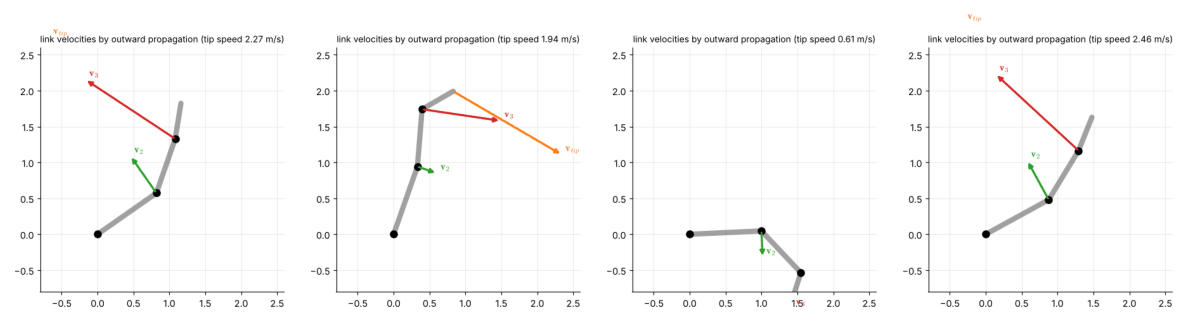

In [6]:
Ls = [1.0, 0.8, 0.5]
table3 = [(0, 0, 0, 0, "R"), (0, Ls[0], 0, 0, "R"), (0, Ls[1], 0, 0, "R"), (0, Ls[2], 0, 0, "R")]   # last row = tip frame (fixed)

def q_traj(s):
    """Joint angles and rates at time t = 2 pi s seconds (one period of the motion per unit of s)."""
    t = 2 * np.pi * s
    q = np.array([deg(35) + deg(40) * np.sin(t), deg(50) * np.sin(t + 0.8), deg(-35) + deg(45) * np.cos(t)])
    qd = np.array([deg(40) * np.cos(t), deg(50) * np.cos(t + 0.8), -deg(45) * np.sin(t)])
    return q, qd

fig, ax = plt.subplots(figsize=(5.6, 5.0))
colors = ["#7f7f7f", "#7f7f7f", "#2ca02c", "#d62728", "#ff7f0e"]

def update(s):
    q, qd = q_traj(s)
    qf, qdf = np.append(q, 0.0), np.append(qd, 0.0)                 # fixed row has zero joint rate
    Ts = fk_dh(table3, qf)
    ws, vs = jc.propagate_velocity(table3, qf, qdf)
    ax.cla()
    P = np.array([T[:3, 3] for T in Ts])
    ax.plot(P[1:, 0], P[1:, 1], "-", color="#555", lw=6, solid_capstyle="round", alpha=0.55)
    ax.plot(P[1:4, 0], P[1:4, 1], "o", color="k", ms=8)
    for i in (2, 3, 4):                                               # link-origin velocities: the origin of {1} is the fixed base
        v0 = Ts[i][:3, :3] @ vs[i]                                    # ^0 v_i = ^0_i R ^i v_i
        ax.annotate("", xy=P[i, :2] + 0.9 * v0[:2], xytext=P[i, :2],
                    arrowprops=dict(arrowstyle="-|>", color=colors[i], lw=2.4))
        ax.text(*(P[i, :2] + 0.9 * v0[:2] + 0.05), (r"$\mathbf{v}_{tip}$" if i == 4 else rf"$\mathbf{{v}}_{i}$"), color=colors[i], fontsize=11)
    ax.set_xlim(-0.8, 2.6); ax.set_ylim(-0.8, 2.6); ax.set_aspect("equal"); ax.grid(alpha=0.25)
    ax.set_title(rf"link velocities by outward propagation (tip speed {np.linalg.norm(vs[4]):.2f} m/s)", fontsize=10)

animate(fig, update, np.linspace(0, 1, 40, endpoint=False), interval=90, gif="assets/5.1-velocity-propagation-3R.gif",
        n_keyframes=4)

**Checking the recursion.** The statement "propagation computes the velocity of the tool" is a claim that can be tested against an independent
calculation: differentiate the forward kinematics numerically. For a chain with arbitrary D-H parameters, including a prismatic joint and an offset
tool, the velocity obtained by propagation (rotated into the base frame) must equal the finite-difference derivative of the tool pose along
$\mathbf q(t)=\mathbf q_0+t\dot{\mathbf q}$.

In [7]:
rng = np.random.default_rng(7)
table = [(rng.uniform(-np.pi, np.pi), rng.uniform(-0.4, 0.4), rng.uniform(-0.4, 0.4), rng.uniform(-np.pi, np.pi), k)
         for k in "RRPRRR"]                                            # a random chain with one prismatic joint
tool = make_T(rotz(0.4) @ rotx(-0.3), [0.05, -0.02, 0.12])
q, qd = rng.uniform(-1, 1, 6), rng.uniform(-1, 1, 6)

ws, vs = jc.propagate_velocity(table, q, qd, tool=tool)               # outward iteration, tool frame appended
T0 = fk_tool(table, q, tool=tool)
v_prop, w_prop = T0[:3, :3] @ vs[-1], T0[:3, :3] @ ws[-1]            # rotate into the base frame

h = 1e-6
Tp, Tm = fk_tool(table, q + h * qd, tool=tool), fk_tool(table, q - h * qd, tool=tool)
v_fd = (Tp[:3, 3] - Tm[:3, 3]) / (2 * h)
w_fd = unskew(((Tp[:3, :3] - Tm[:3, :3]) / (2 * h)) @ T0[:3, :3].T)
print("tool linear velocity, propagation:", v_prop.round(5), "\n                    finite difference:", v_fd.round(5))
print("tool angular velocity, propagation:", w_prop.round(5), "\n                     finite difference:", w_fd.round(5))
print("agree:", np.allclose(v_prop, v_fd, atol=1e-7) and np.allclose(w_prop, w_fd, atol=1e-7))

tool linear velocity, propagation: [0.9321 0.5622 0.467 ] 
                    finite difference: [0.9321 0.5622 0.467 ]
tool angular velocity, propagation: [-1.1585  0.4304  1.0355] 
                     finite difference: [-1.1585  0.4304  1.0355]
agree: True


## 8. A real robot: the UR5e flange velocity

The **Universal Robots UR5e** in MuJoCo Menagerie has six revolute joints. Following the frame-assignment rules of Chapter 3 one reads
from the model file the modified D-H table below (relative to the model's `base` body, whose frame is turned by $180^\circ$ about $\hat Z$
from the world frame), together with a fixed transform to the model's `attachment_site`, the tool flange. The table is stored in
`rgkit.jacobian.UR5E_DH`:

| $i$ | $\alpha_{i-1}$ | $a_{i-1}$ (m) | $d_i$ (m) | $\theta_i$ |
|:--:|:--:|:--:|:--:|:--:|
| 1 | $0$ | $0$ | $0.163$ | $q_1$ |
| 2 | $-90^\circ$ | $0$ | $0.138$ | $q_2$ |
| 3 | $0$ | $0.425$ | $-0.131$ | $q_3$ |
| 4 | $0$ | $0.392$ | $0.127$ | $q_4$ |
| 5 | $-90^\circ$ | $0$ | $0.100$ | $q_5$ |
| 6 | $+90^\circ$ | $0$ | $0$ | $q_6$ |

Flange: ${}^{6}_{T}T=\mathrm{Trans}(0,0,0.1)\,R_Z(180^\circ)$. (The values $0.138-0.131$ and $0.127$ reflect the lateral offsets of the real
UR arm; the dimensions are those of the Menagerie model and differ slightly from Universal Robots' calibration figures.)

We test the claim of Section 6 in three independent ways, for a random configuration $\mathbf q$ and random joint rates $\dot{\mathbf q}$:

1. **propagation** through the D-H table (our code, in the tool frame);
2. **MuJoCo's own velocity calculation**: set `data.qvel`, call `mj_forward` and read the site velocity with `mj_objectVelocity` (MuJoCo stores
   the result as $[\boldsymbol\omega;\ \mathbf v]$, angular part first — note the order — and can express it in the site's local frame);
3. **finite differences** of the simulated site pose, obtained by evaluating MuJoCo's forward kinematics at $\mathbf q\pm h\dot{\mathbf q}$.

In [8]:
from rgkit import robots, mujoco_utils as mju
import mujoco

model, data = robots.load_robot("ur5e")
site_id = model.site("attachment_site").id
R_wb = jc.UR5E_BASE_IN_WORLD[:3, :3]                                   # base body frame in the world frame

rng = np.random.default_rng(11)
q, qd = rng.uniform(-2, 2, 6), rng.uniform(-1, 1, 6)

# (0) the D-H model reproduces MuJoCo's forward kinematics
data.qpos[:] = q; mujoco.mj_forward(model, data)
T_dh = jc.UR5E_BASE_IN_WORLD @ fk_tool(jc.UR5E_DH, q, tool=jc.UR5E_TOOL)
print("D-H forward kinematics = MuJoCo site pose:",
      np.allclose(T_dh[:3, 3], data.site_xpos[site_id], atol=1e-9) and np.allclose(T_dh[:3, :3], data.site_xmat[site_id].reshape(3, 3), atol=1e-9))

# (1) propagation, described in the tool frame
ws, vs = jc.propagate_velocity(jc.UR5E_DH, q, qd, tool=jc.UR5E_TOOL)
v1, w1 = vs[-1], ws[-1]

# (2) MuJoCo: velocity of the site, local frame, order [angular; linear]
data.qvel[:] = qd; mujoco.mj_forward(model, data)
res = np.zeros(6); mujoco.mj_objectVelocity(model, data, mujoco.mjtObj.mjOBJ_SITE, site_id, res, 1)
w2, v2 = res[:3], res[3:]

# (3) finite differences of the simulated site pose, then described in the tool frame
def site_pose(qq):
    d2 = mujoco.MjData(model); d2.qpos[:] = qq; mujoco.mj_forward(model, d2)
    return d2.site_xpos[site_id].copy(), d2.site_xmat[site_id].reshape(3, 3).copy()
h = 1e-6
(pp, Rp), (pm, Rm) = site_pose(q + h * qd), site_pose(q - h * qd)
R_t = data.site_xmat[site_id].reshape(3, 3)
v3 = R_t.T @ ((pp - pm) / (2 * h))
w3 = R_t.T @ unskew(((Rp - Rm) / (2 * h)) @ R_t.T)

print(f"{'':28s}{'v (m/s)':>30s}{'omega (rad/s)':>34s}")
for name, v_, w_ in [("D-H propagation", v1, w1), ("MuJoCo mj_objectVelocity", v2, w2), ("finite differences", v3, w3)]:
    print(f"{name:28s}{np.array2string(v_, precision=5):>30s}{np.array2string(w_, precision=5):>34s}")
print("all three agree:", np.allclose(v1, v2, atol=1e-9) and np.allclose(w1, w2, atol=1e-9) and np.allclose(v1, v3, atol=1e-6) and np.allclose(w1, w3, atol=1e-6))

D-H forward kinematics = MuJoCo site pose: True
                                                   v (m/s)                     omega (rad/s)
D-H propagation               [-0.14465 -0.7194  -0.34541]         [0.22035 0.22734 0.932  ]
MuJoCo mj_objectVelocity      [-0.14465 -0.7194  -0.34541]         [0.22035 0.22734 0.932  ]
finite differences            [-0.14465 -0.7194  -0.34541]         [0.22035 0.22734 0.932  ]
all three agree: True


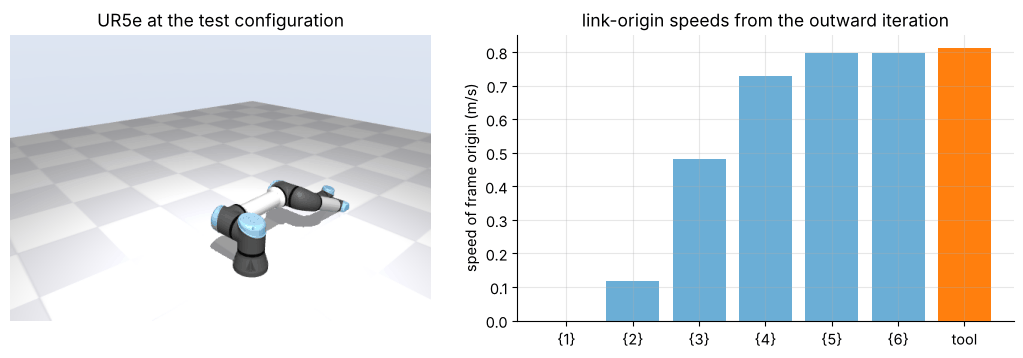

Universal Robots UR5e — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/universal_robots_ur5e) (Universal Robots; licence: BSD-3-Clause)


In [9]:
# Show the arm at the configuration used above, and the velocity of every link frame origin from propagation
data.qpos[:] = q; data.qvel[:] = 0; mujoco.mj_forward(model, data)
img = mju.render(model, data, camera=dict(azimuth=140, elevation=-22, distance=1.5, lookat=(-0.2, 0.0, 0.35)), width=560, height=380)
Ts_all = fk_dh(jc.UR5E_DH, q)
speeds = [np.linalg.norm(v) for v in vs[1:7]]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7), gridspec_kw={"width_ratios": [1, 1.1]})
axes[0].imshow(img); axes[0].set_axis_off(); axes[0].set_title("UR5e at the test configuration")
axes[1].bar(range(1, 7), speeds, color="#6baed6")
axes[1].bar([7], [np.linalg.norm(v1)], color="#ff7f0e")
axes[1].set_xticks(range(1, 8)); axes[1].set_xticklabels([f"{{{i}}}" for i in range(1, 7)] + ["tool"])
axes[1].set_ylabel("speed of frame origin (m/s)"); axes[1].set_title("link-origin speeds from the outward iteration")
plt.tight_layout(); plt.show()
print(robots.describe("ur5e"))

All three methods agree to the accuracy of the finite difference ($\sim10^{-9}$ m/s), so the recursion of Section 6 — written once for a
generic D-H table — describes a real, manufacturer-modelled arm. Note the roles of the frames: our result is described in the **tool frame**
(MuJoCo's `local` option), because that is where the recursion naturally ends; the world-frame description is obtained by one rotation
${}^{0}_{T}R$, as in the finite-difference lines. In Notebook 5.3 the choice of frame becomes the central topic.

## 9. Worked examples

**Example 5.1.1 — velocity of a point on a rotating body.** A rigid body turns about the origin of $\{A\}$ with angular velocity
$\boldsymbol\omega=2\,\hat Z$ rad/s. Frame $\{B\}$ is fixed in the body and is at this instant rotated $30^\circ$ about $\hat Z_A$ relative to
$\{A\}$. A point has ${}^{B}Q=(0.5,\ 0.2,\ 0)$ m. Find its velocity ${}^{A}V_Q$.

*Solution.* ${}^{A}Q = R_Z(30^\circ){}^{B}Q=(0.5\cos30^\circ-0.2\sin30^\circ,\ 0.5\sin30^\circ+0.2\cos30^\circ,\ 0)=(0.3330,\ 0.4232,\ 0)$ m. The
point is fixed in the body, so ${}^{A}V_Q=\boldsymbol\omega\times{}^{A}Q = 2\,(-0.4232,\ 0.3330,\ 0)=(-0.8464,\ 0.6660,\ 0)$ m/s. Its speed is
$\omega\lVert Q\rVert=2(0.5385)=1.077$ m/s.

**Example 5.1.2 — a point that slides on a moving body.** The origin of $\{B\}$ moves with ${}^{A}V_{BORG}=(1,0,0)$ m/s while $\{B\}$ turns with
$\boldsymbol\omega=(0,0,1)$ rad/s; at the instant considered ${}^{A}_{B}R=I$. A bead at ${}^{B}Q=(0.4,0,0)$ m slides along $\hat Y_B$ with ${}^{B}V_Q=(0,0.3,0)$ m/s. Find
${}^{A}V_Q$.

*Solution.* From the general velocity formula,
${}^{A}V_Q=(1,0,0)+(0,0.3,0)+(0,0,1)\times(0.4,0,0)=(1,\ 0.3+0.4,\ 0)=(1,\ 0.7,\ 0)$ m/s. The last term, $(0,0.4,0)$, is the part that the rotation adds.

**Example 5.1.3 — adding angular velocities.** Frame $\{B\}$ rotates about $\hat Z_A$ at 1 rad/s and at $t=0$ is rotated $90^\circ$ about $\hat X_A$ relative to $\{A\}$. Frame $\{C\}$ rotates
relative to $\{B\}$ about $\hat Z_B$ at 2 rad/s. Find ${}^{A}\Omega_C$ at $t=0$.

*Solution.* ${}^{A}\Omega_B=(0,0,1)$ and ${}^{A}_{B}R\,{}^{B}\Omega_C=R_X(90^\circ)(0,0,2)=(0,-2,0)$, so ${}^{A}\Omega_C=(0,\ -2,\ 1)$ rad/s, of magnitude $\sqrt5=2.236$ rad/s.

**Example 5.1.4 — two-link arm, propagation with numbers.** For $L_1=1.0$ m, $L_2=0.8$ m, $\theta_1=30^\circ$, $\theta_2=60^\circ$, $\dot\theta_1=1.0$ rad/s and
$\dot\theta_2=0.5$ rad/s, find the tip velocity in the tool frame $\{3\}$ and in the base frame.

*Solution.* From Section 7: ${}^{3}\mathbf v_3=\big(L_1\sin\theta_2\dot\theta_1,\ L_1\cos\theta_2\dot\theta_1+L_2(\dot\theta_1+\dot\theta_2),\ 0\big)=(0.8660,\ 0.5+1.2,\ 0)=(0.8660,\ 1.7000,\ 0)$ m/s. The tool frame is rotated
$\theta_1+\theta_2=90^\circ$ from the base, so ${}^{0}\mathbf v_3=R_Z(90^\circ){}^{3}\mathbf v_3=(-1.7000,\ 0.8660,\ 0)$ m/s and the tip speed is $1.908$ m/s.

**Example 5.1.5 — a polar (RP) arm.** A planar arm has a revolute joint turning link 2, along which a prismatic joint extends the tip to a distance $d$ from the shoulder. At
$\theta=40^\circ$, $d=0.6$ m, $\dot\theta=0.5$ rad/s and $\dot d=0.2$ m/s find the tip velocity.

*Solution.* In polar form the velocity has a radial part $\dot d\,\hat r$ and a tangential part $d\dot\theta\,\hat\theta$:
$\mathbf v=0.2(\cos40^\circ,\sin40^\circ)+0.3(-\sin40^\circ,\cos40^\circ)=(-0.0396,\ 0.3584)$ m/s. The outward iteration with the D-H rows
$(0,0,0,-90^\circ,R)$ and $(-90^\circ,0,0,0,P)$ gives the same result, and shows how the prismatic rate enters through $\dot d\,\hat Z_2$.

In [10]:
# Example 5.1.1
w = np.array([0, 0, 2.0]); QB = np.array([0.5, 0.2, 0]); QA = rotz(deg(30)) @ QB
vQ = np.cross(w, QA)
print("5.1.1  A_Q =", QA.round(4), " v =", vQ.round(4), " speed =", np.linalg.norm(vQ).round(3))
assert np.allclose(QA, [0.3330, 0.4232, 0], atol=1e-4) and np.allclose(vQ, [-0.8464, 0.6660, 0], atol=1e-4)
# check by numerical differentiation of a rotating body
R_t = lambda t: rotz(deg(30) + 2.0 * t)
assert np.allclose(((R_t(1e-6) - R_t(-1e-6)) / 2e-6) @ QB, vQ, atol=1e-6)

# Example 5.1.2 (verify by differentiating the position of the bead)
def Q_pos(t):
    th = 1.0 * t                                               # B turns at 1 rad/s, R = I at t = 0
    origin = np.array([1.0 * t, 0, 0])
    QBt = np.array([0.4, 0.3 * t, 0])
    return origin + rotz(th) @ QBt
v_num = (Q_pos(1e-6) - Q_pos(-1e-6)) / 2e-6
print("5.1.2  v =", v_num.round(4)); assert np.allclose(v_num, [1.0, 0.7, 0.0], atol=1e-6)

# Example 5.1.3
Om = np.array([0, 0, 1.0]) + rotx(deg(90)) @ np.array([0, 0, 2.0])
RAC = lambda t: rotz(t) @ rotx(deg(90)) @ rotz(2 * t)
w_num = unskew(((RAC(1e-6) - RAC(-1e-6)) / 2e-6) @ RAC(0).T)
print("5.1.3  A_Omega_C =", Om.round(4), " |.| =", np.linalg.norm(Om).round(4))
assert np.allclose(Om, [0, -2, 1], atol=1e-9) and np.allclose(w_num, Om, atol=1e-6)

# Example 5.1.4
tab2 = [(0, 0, 0, 0, "R"), (0, 1.0, 0, 0, "R"), (0, 0.8, 0, 0, "R")]
q2, qd2 = [deg(30), deg(60), 0], [1.0, 0.5, 0.0]
ws2, vs2 = jc.propagate_velocity(tab2, q2, qd2)
v_tool = vs2[-1]; T2 = fk_dh(tab2, q2)[-1]; v_base = T2[:3, :3] @ v_tool
print("5.1.4  ^3v_3 =", v_tool.round(4), " ^0v_3 =", v_base.round(4), " speed =", np.linalg.norm(v_base).round(3))
assert np.allclose(v_tool, [0.8660, 1.7, 0], atol=1e-4) and np.allclose(v_base, [-1.7, 0.8660, 0], atol=1e-4)
J2 = jc.planar_jacobian([1.0, 0.8], q2[:2]); assert np.allclose(J2 @ qd2[:2], v_base[:2])

# Example 5.1.5: polar arm
polar = [(0, 0, 0, -np.pi / 2, "R"), (-np.pi / 2, 0, 0, 0, "P")]
th, d_, thd, dd = deg(40), 0.6, 0.5, 0.2
ws3, vs3 = jc.propagate_velocity(polar, [th, d_], [thd, dd])
T3 = fk_dh(polar, [th, d_])[-1]
v_polar = (T3[:3, :3] @ vs3[-1])[:2]
v_formula = dd * np.array([np.cos(th), np.sin(th)]) + d_ * thd * np.array([-np.sin(th), np.cos(th)])
print("5.1.5  v =", v_polar.round(4), " tip at", T3[:2, 3].round(4), "=", (d_ * np.array([np.cos(th), np.sin(th)])).round(4))
assert np.allclose(v_polar, v_formula) and np.allclose(v_formula, [-0.0396, 0.3584], atol=1e-4)
print("all worked examples verified")

5.1.1  A_Q = [0.333  0.4232 0.    ]  v = [-0.8464  0.666   0.    ]  speed = 1.077
5.1.2  v = [1.  0.7 0. ]
5.1.3  A_Omega_C = [ 0. -2.  1.]  |.| = 2.2361
5.1.4  ^3v_3 = [0.866 1.7   0.   ]  ^0v_3 = [-1.7    0.866  0.   ]  speed = 1.908
5.1.5  v = [-0.0396  0.3584]  tip at [0.4596 0.3857] = [0.4596 0.3857]
all worked examples verified


## 10. Summary

| Result | Formula |
|:--|:--|
| Angular velocity | $\dot R R^{\mathsf T}=[\boldsymbol\omega]_\times$ (described in the fixed frame); $R^{\mathsf T}\dot R=[R^{\mathsf T}\boldsymbol\omega]_\times$ (described in the body) |
| Body-fixed vector | $\dot{\mathbf p}=\boldsymbol\omega\times\mathbf p$ |
| Rigid-body velocity | $\mathbf v_Q=\mathbf v_O+\boldsymbol\omega\times\mathbf r_{OQ}$; $\boldsymbol\omega$ is the same for all points |
| Sliding point | ${}^{A}V_Q={}^{A}V_{BORG}+{}^{A}_{B}R\,{}^{B}V_Q+{}^{A}\Omega_B\times{}^{A}_{B}R\,{}^{B}Q$ |
| Addition | ${}^{A}\Omega_C={}^{A}\Omega_B+{}^{A}_{B}R\,{}^{B}\Omega_C$ (same frame only) |
| Propagation, revolute | ${}^{i+1}\boldsymbol\omega_{i+1}={}^{i+1}_iR\,{}^{i}\boldsymbol\omega_i+\dot\theta_{i+1}\hat Z$; ${}^{i+1}\mathbf v_{i+1}={}^{i+1}_iR({}^{i}\mathbf v_i+{}^{i}\boldsymbol\omega_i\times{}^{i}P_{i+1})$ |
| Propagation, prismatic | same, with $+\dot d_{i+1}\hat Z$ added to ${}^{i+1}\mathbf v_{i+1}$ and no $\dot\theta$ term |
| Tool velocity | linear in $\dot{\mathbf q}$; the coefficient matrix is the Jacobian (next notebook) |

### Common mistakes

* Treating Euler-angle rates $(\dot\alpha,\dot\beta,\dot\gamma)$ as the components of $\boldsymbol\omega$.
* Adding angular velocities that are described in different frames, or forgetting the rotation ${}^{A}_{B}R$ in the sum.
* Forgetting the term $\boldsymbol\omega\times\mathbf r$: a rotating link moves points *away* from the axis, not only the origin.
* Mixing the descriptions: the outward iteration leaves ${}^{i}\mathbf v_i$ in frame $\{i\}$; rotate by ${}^{0}_{i}R$ before plotting in the base frame.
* Reading MuJoCo's `mj_objectVelocity` output as $[\mathbf v;\ \boldsymbol\omega]$: it is $[\boldsymbol\omega;\ \mathbf v]$.

## Exercises

**5.1.1** Show that for a rotation $R(t)=\mathrm{Rot}(\hat K,\theta(t))$ about a fixed unit axis $\hat K$ one has $\dot R R^{\mathsf T}=\dot\theta\,[\hat K]_\times$, and
hence $\boldsymbol\omega=\dot\theta\hat K$.

<details><summary>Answer</summary>

Rodrigues' formula gives $R=I+\sin\theta\,K+(1-\cos\theta)K^2$ with $K=[\hat K]_\times$, $K^3=-K$. Then
$\dot R=\dot\theta(\cos\theta\,K+\sin\theta\,K^2)$ and $R^{\mathsf T}=I-\sin\theta K+(1-\cos\theta)K^2$. Multiplying and using $K^3=-K$, $K^4=-K^2$:
$\dot R R^{\mathsf T}=\dot\theta K$, i.e. $\boldsymbol\omega=\dot\theta\hat K$. (Checked numerically below for an arbitrary axis.)
</details>

**5.1.2** A turntable rotates at $\boldsymbol\omega=(0,0,3)$ rad/s about its centre, which is at rest. A bug walks radially outward along the table at $0.1$ m/s (relative
to the table) and is at ${}^{B}Q=(0.2,0,0)$ when the table-fixed axis $\hat X_B$ coincides with $\hat X_A$. Find the bug's velocity in $\{A\}$ and its speed.

<details><summary>Answer</summary>

${}^{A}V_Q=\mathbf 0+(0.1,0,0)+(0,0,3)\times(0.2,0,0)=(0.1,\ 0.6,\ 0)$ m/s; speed $\sqrt{0.01+0.36}=0.608$ m/s.
</details>

**5.1.3** Frame $\{B\}$ turns about $\hat Y_A$ at $1.5$ rad/s; frame $\{C\}$ turns relative to $\{B\}$ about $\hat X_B$ at $0.8$ rad/s. At an instant when
${}^{A}_{B}R=R_Y(90^\circ)$, find ${}^{A}\Omega_C$.

<details><summary>Answer</summary>

${}^{A}\Omega_B=(0,1.5,0)$; $R_Y(90^\circ)(0.8,0,0)^{\mathsf T}=(0,0,-0.8)$ (the first column of $R_Y(90^\circ)$ is $(0,0,-1)$). Hence ${}^{A}\Omega_C=(0,\ 1.5,\ -0.8)$ rad/s.
</details>

**5.1.4** A planar three-link arm has $L=(1.0,\,0.8,\,0.5)$ m, $\mathbf q=(30^\circ,\,-20^\circ,\,50^\circ)$ and $\dot{\mathbf q}=(0.4,\,-0.2,\,0.6)$ rad/s. Using the outward
iteration, find the tip velocity in the base frame and the angular velocity of link 3.

<details><summary>Answer</summary>

${}^{0}\mathbf v_{tip}=(-0.5742,\ 0.7040,\ 0)$ m/s (speed $0.908$ m/s), obtained by the three outward steps and confirmed by $J\dot{\mathbf q}$ with the planar Jacobian
(verification cell below); the angular velocity of link 3 is $\dot\theta_1+\dot\theta_2+\dot\theta_3=0.4-0.2+0.6=0.8$ rad/s about $\hat Z$.
</details>

**5.1.5** For the polar arm of Example 5.1.5, show that the outward iteration reproduces $\mathbf v=\dot d\,\hat r+d\dot\theta\,\hat\theta$ symbolically.

<details><summary>Answer</summary>

Frame {1} has ${}^{1}\boldsymbol\omega_1=(0,0,\dot\theta)$, ${}^{1}\mathbf v_1=\mathbf 0$. The link transform to {2} is $R_X(-90^\circ)D_Z(d)$, so ${}^{1}P_2=(0,\,d,\,0)$ and ${}^{2}_{1}R=R_X(-90^\circ)^{\mathsf T}$. Then
${}^{1}\mathbf v_1+{}^{1}\boldsymbol\omega_1\times{}^{1}P_2=(0,0,\dot\theta)\times(0,d,0)=(-d\dot\theta,\,0,\,0)$, and the prismatic term adds $\dot d\,\hat Z_2$, giving
${}^{2}\mathbf v_2=(-d\dot\theta,\,0,\,\dot d)$. Written back in frame {1} this is $(-d\dot\theta,\ \dot d,\ 0)$. The $\hat Y_1$ axis of this table points radially outward and $\hat X_1$ is minus the tangential direction, so
$\mathbf v=\dot d\,\hat r+d\dot\theta\,\hat\theta$. (Verified symbolically in the cell below.)
</details>

**5.1.6** (*Programming*) Write your own `propagate(table, q, qd)` for revolute joints only, using `fk_dh` to obtain ${}^{i}_{i+1}T$, and test it against `rgkit.jacobian.propagate_velocity` for a random six-joint table.

<details><summary>Answer</summary>

Loop over rows: `T = dh_modified(alpha, a, d, theta + q_i)`, `R, P = T[:3,:3].T, T[:3,3]`, `v = R @ (v + np.cross(w, P))`, `w = R @ w + qd_i * z`. The check cell below does this and prints the largest difference.
</details>

**5.1.7** (*MuJoCo*) In the UR5e cell of Section 8 set only $\dot q_1=1$ rad/s (all other rates zero). Predict the speed of the flange from the geometry
(distance from the flange to the axis of joint 1) and confirm it with the simulator.

<details><summary>Answer</summary>

Only the base joint turns, so every point moves on a circle about the vertical axis through the base origin: speed $=\dot q_1\,\rho$, where $\rho$ is the horizontal distance of the flange from that axis. The cell below prints
$\rho=\sqrt{x^2+y^2}$ of the flange and the speed from the simulator; they agree.
</details>

In [11]:
# --- verification of the exercise answers ---------------------------------------------------------------
# 5.1.1  Rodrigues derivative for an arbitrary axis
k = np.array([1.0, -2.0, 0.5]); k /= np.linalg.norm(k)
R_k = lambda th: rot_axis_angle(k, th)
th0, thd = 0.9, 1.7
Rdot = (R_k(th0 + 1e-6 * thd) - R_k(th0 - 1e-6 * thd)) / 2e-6
print("5.1.1  Rdot R^T = thd [k]x :", np.allclose(Rdot @ R_k(th0).T, thd * skew(k), atol=1e-7))

# 5.1.2
v = np.array([0.1, 0, 0]) + np.cross([0, 0, 3.0], [0.2, 0, 0])
print("5.1.2  v =", v, " speed =", np.linalg.norm(v).round(3)); assert np.allclose(v, [0.1, 0.6, 0]) and abs(np.linalg.norm(v) - 0.608) < 1e-3

# 5.1.3
Om = np.array([0, 1.5, 0]) + roty(deg(90)) @ np.array([0.8, 0, 0])
print("5.1.3  A_Omega_C =", Om.round(4)); assert np.allclose(Om, [0, 1.5, -0.8], atol=1e-12)

# 5.1.4
tab3 = [(0, 0, 0, 0, "R"), (0, 1.0, 0, 0, "R"), (0, 0.8, 0, 0, "R"), (0, 0.5, 0, 0, "R")]
q4, qd4 = np.array([deg(30), deg(-20), deg(50), 0.0]), np.array([0.4, -0.2, 0.6, 0.0])
ws4, vs4 = jc.propagate_velocity(tab3, q4, qd4)
T4 = fk_dh(tab3, q4)[-1]; vb = T4[:3, :3] @ vs4[-1]
Jp = jc.planar_jacobian([1.0, 0.8, 0.5], q4[:3])
print("5.1.4  v_tip =", vb.round(4), " omega_3 =", ws4[3][2].round(4))
assert np.allclose(vb[:2], Jp @ qd4[:3]) and np.isclose(ws4[3][2], 0.8)
print("       (the value quoted in the answer)", vb.round(4))

# 5.1.5 symbolic polar-arm check
th_s, d_s, thd_s, dd_s = sp.symbols("theta d thetadot ddot", real=True)
Rx_m90 = sp.Matrix([[1, 0, 0], [0, 0, 1], [0, -1, 0]])                      # Rx(-90 deg)
w1s, v1s = sp.Matrix([0, 0, thd_s]), sp.zeros(3, 1)
P2 = sp.Matrix([0, d_s, 0]); R21 = Rx_m90.T
v2s = sp.simplify(R21 * (v1s + w1s.cross(P2)) + dd_s * sp.Matrix([0, 0, 1]))
v2_in_1 = sp.simplify(R21.T * v2s)                                           # back to frame {1}: (-d thd, ddot, 0)
print("5.1.5  ^1 v_2 =", list(v2_in_1), " (frame {1}: Y1 is radial, X1 is minus tangential)")
assert list(v2_in_1) == [-d_s * thd_s, dd_s, 0]

# 5.1.6 own implementation
from rgkit.kinematics import dh_modified
def propagate(table, q, qd):
    w, v = np.zeros(3), np.zeros(3)
    for (al, a, d, th, kind), qi, qdi in zip(table, q, qd):
        T = dh_modified(al, a, d, th + qi)
        R, P = T[:3, :3].T, T[:3, 3]
        v = R @ (v + np.cross(w, P)); w = R @ w + qdi * np.array([0, 0, 1.0])
    return v, w
tabR = [(rng.uniform(-3, 3), rng.uniform(-.4, .4), rng.uniform(-.4, .4), rng.uniform(-3, 3), "R") for _ in range(6)]
qq, qqd = rng.uniform(-1, 1, 6), rng.uniform(-1, 1, 6)
ws_, vs_ = jc.propagate_velocity(tabR, qq, qqd); vv, ww = propagate(tabR, qq, qqd)
print("5.1.6  max difference:", max(np.abs(vv - vs_[-1]).max(), np.abs(ww - ws_[-1]).max()))

# 5.1.7 MuJoCo: only joint 1 turning
qd_only1 = np.array([1.0, 0, 0, 0, 0, 0])
data.qpos[:] = q; data.qvel[:] = qd_only1; mujoco.mj_forward(model, data)
res = np.zeros(6); mujoco.mj_objectVelocity(model, data, mujoco.mjtObj.mjOBJ_SITE, site_id, res, 0)
rho = np.hypot(*data.site_xpos[site_id][:2])
print(f"5.1.7  rho = {rho:.4f} m, MuJoCo speed = {np.linalg.norm(res[3:]):.4f} m/s")
assert np.isclose(np.linalg.norm(res[3:]), rho)
data.qvel[:] = 0

5.1.1  Rdot R^T = thd [k]x : True
5.1.2  v = [0.1 0.6 0. ]  speed = 0.608
5.1.3  A_Omega_C = [ 0.   1.5 -0.8]
5.1.4  v_tip = [-0.5742  0.704   0.    ]  omega_3 = 0.8
       (the value quoted in the answer) [-0.5742  0.704   0.    ]
5.1.5  ^1 v_2 = [-d*thetadot, ddot, 0]  (frame {1}: Y1 is radial, X1 is minus tangential)
5.1.6  max difference: 0.0
5.1.7  rho = 0.8892 m, MuJoCo speed = 0.8892 m/s


## Further reading and lectures

* Craig, Ch. 5, §5.1–5.5 (velocity of rigid bodies and propagation); Lynch & Park §3.2.2 and §3.3.2; Siciliano et al. Ch. 3; Corke *RVC* Ch. 8.
* Video: [Modern Robotics — Ch. 5 Velocity kinematics and statics](https://www.youtube.com/watch?v=6tj8QLF69Ok); [Modern Robotics — 3.2.2 Angular velocities](https://www.youtube.com/watch?v=zJJldJYMxVU); [Modern Robotics — 3.3.2 Twists (part 1)](https://www.youtube.com/watch?v=mvGZtO_ruj0); [Modern Robotics — 3.3.2 Twists (part 2)](https://www.youtube.com/watch?v=VTv0qmLNvjg); [ThatsEngineering — Jacobian matrix and singularities (part 1)](https://www.youtube.com/watch?v=h2YM0CDzDl4).
* MuJoCo documentation: [mujoco.readthedocs.io](https://mujoco.readthedocs.io/) (see `mj_objectVelocity` in the API reference).

---

[Chapter contents](README.md) &nbsp;·&nbsp; [5.2 The Manipulator Jacobian →](5.2-the-manipulator-jacobian.ipynb)